# Paper Plots

Experiment logs: `/nfs/scistore19/locatgrp/fmontagn/mcd/outputs/paper/nn_residual`

- **mcd** (= mcd-hsic) uses n_envs = 3; all other algorithms use n_envs = 1.
- Each plot averages over all repetitions (and hyperparameter seeds where applicable).

In [89]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "figure.dpi": 120,
})

BASE = Path("/nfs/scistore19/locatgrp/fmontagn/mcd/outputs/paper/nn_residual")

def load_csv(algorithm, n_envs, mechanism):
    path = BASE / algorithm / f"nenvs{n_envs}" / mechanism / "metrics.csv"
    if not path.exists():
        print(f"Warning: {path} not found")
        return None
    return pd.read_csv(path)

def ci95(values):
    n = len(values)
    if n < 2:
        return 0.0
    return 1.96 * np.std(values, ddof=1) / np.sqrt(n)

def style_ax(ax):
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis='y', length=0)

def fix_legend(leg):
    leg.get_frame().set_alpha(1)
    for handle in leg.legend_handles:
        if hasattr(handle, 'set_edgecolor') and hasattr(handle, 'get_facecolor'):
            handle.set_edgecolor(handle.get_facecolor())

ERR_KW = {"linewidth": 0.8, "capsize": 2, "capthick": 0.8, "solid_capstyle": "butt"}

PLOTS_DIR = Path("outputs/plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)


## 1. Main comparison — all algorithms on nn_residual data

One bar chart per n_samples. X: number of nodes. Five bars per group: cam, lingam, mcd, nogam, resit. Bar height = mean Dtop; error bar = 95 % CI.

In [ ]:
# mcd-hsic uses n_envs=3; all other algorithms use n_envs=1
# nogam's 3000-sample run lives in not_obs_id; supplement nn_residual with those rows
dfs = []
for alg in ["cam", "lingam", "resit"]:
    df = load_csv(alg, 1, "nn_residual")
    if df is not None:
        dfs.append(df)

df_nogam = load_csv("nogam", 1, "nn_residual")
df_nogam_3k = load_csv("nogam", 1, "not_obs_id")
if df_nogam is not None and df_nogam_3k is not None:
    dfs.append(pd.concat([df_nogam, df_nogam_3k[df_nogam_3k["n_samples"] == 3000]], ignore_index=True))
elif df_nogam is not None:
    dfs.append(df_nogam)

df_mcd = load_csv("mcd-hsic", 3, "nn_residual")
if df_mcd is not None:
    dfs.append(df_mcd)

data = pd.concat(dfs, ignore_index=True)
data["algorithm"] = data["algorithm"].replace({"mcd-hsic": "mcd"})

ALG_ORDER = ["mcd", "cam", "lingam", "nogam", "resit"]
ALG_LABELS = {
    "mcd":    "mcd (ours)",
    "cam":    "cam",
    "lingam": "lingam",
    "nogam":  "nogam",
    "resit":  "resit",
}
ALG_COLORS = {
    "mcd":    "#52AEA0",
    "cam":    "#E07558",
    "lingam": "#EAB84A",
    "nogam":  "#7EB5D6",
    "resit":  "#C080A0",
}

d_values = sorted(data["d"].unique())
n_samples_values = sorted(data["n_samples"].unique())
bar_width = 0.15
x = np.arange(len(d_values))
n_algs = len(ALG_ORDER)

for n_samp in n_samples_values:
    fig, ax = plt.subplots(figsize=(10, 4.5))
    style_ax(ax)
    sub = data[data["n_samples"] == n_samp]

    for i, alg in enumerate(ALG_ORDER):
        means, cis = [], []
        for d in d_values:
            vals = sub.loc[(sub["algorithm"] == alg) & (sub["d"] == d), "dtop"].values
            if len(vals) == 0:
                means.append(np.nan)
                cis.append(0.0)
            else:
                means.append(np.nanmean(vals))
                cis.append(ci95(vals))

        offsets = x + (i - (n_algs - 1) / 2) * bar_width
        valid = np.array([not np.isnan(m) for m in means])
        ax.bar(
            offsets[valid], np.array(means)[valid],
            width=bar_width, label=ALG_LABELS[alg], color=ALG_COLORS[alg],
            edgecolor="white", linewidth=2,
            yerr=np.array(cis)[valid],
            capsize=ERR_KW["capsize"], error_kw=ERR_KW, zorder=3,
        )

    ax.set_xlabel("Number of nodes")
    ax.set_ylabel("Dtop")
    ax.set_ylim(0, 1.0)
    ax.set_yticks(np.arange(0, 1.01, 0.1))
    ax.set_xticks(x)
    ax.set_xticklabels(d_values)
    ax.set_title(f"n_samples = {n_samp:,}")
    fix_legend(ax.legend(loc="upper right"))
    ax.grid(axis="y", alpha=0.3, zorder=0)
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / f"paper_comparison_n{n_samp}.pdf", bbox_inches="tight")
    plt.show()


In [ ]:
## 1b. Same comparison — line+marker style (one figure per n_samples)

ALG_MARKERS = {
    "mcd":    "o",
    "cam":    "s",
    "lingam": "^",
    "nogam":  "D",
    "resit":  "v",
    "random": "x",
}
ALG_LINESTYLES = {
    "mcd":    "-",
    "cam":    "--",
    "lingam": "--",
    "nogam":  "--",
    "resit":  "--",
    "random": "none",
}
ALG_LINEWIDTHS = {
    "mcd":    2.5,
    "cam":    1.5,
    "lingam": 1.5,
    "nogam":  1.5,
    "resit":  1.5,
    "random": 0,
}
ALG_COLORS_LINE = {**ALG_COLORS, "random": "#999999"}
ALG_LABELS_LINE = {**ALG_LABELS, "random": "random"}

for n_samp in n_samples_values:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    style_ax(ax)
    sub = data[data["n_samples"] == n_samp]

    for alg in ALG_ORDER:
        means, cis = [], []
        for d in d_values:
            vals = sub.loc[(sub["algorithm"] == alg) & (sub["d"] == d), "dtop"].values
            if len(vals) == 0:
                means.append(np.nan)
                cis.append(0.0)
            else:
                means.append(np.nanmean(vals))
                cis.append(ci95(vals))

        means = np.array(means)
        cis   = np.array(cis)
        valid = ~np.isnan(means)
        ax.plot(
            np.array(d_values)[valid], means[valid],
            linestyle=ALG_LINESTYLES[alg], marker=ALG_MARKERS[alg],
            color=ALG_COLORS_LINE[alg], linewidth=ALG_LINEWIDTHS[alg],
            markersize=6, label=ALG_LABELS_LINE[alg], zorder=3,
        )
        ax.fill_between(
            np.array(d_values)[valid],
            (means - cis)[valid], (means + cis)[valid],
            color=ALG_COLORS_LINE[alg], alpha=0.15, zorder=2,
        )

    # random baseline: one cross per tick at 0.5, no connecting line
    ax.plot(
        d_values, [0.5] * len(d_values),
        linestyle="none", marker="x", color="#999999",
        markersize=7, markeredgewidth=1.8, label="random", zorder=3,
    )

    ax.set_xlabel("Number of nodes")
    ax.set_ylabel("Dtop")
    ax.set_ylim(0, 1.0)
    ax.set_yticks(np.arange(0, 1.01, 0.1))
    ax.set_xticks(d_values)
    leg = ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.06), ncol=6, framealpha=1)
    fix_legend(leg)
    ax.grid(alpha=0.3, zorder=0)
    plt.tight_layout()
    plt.savefig(PLOTS_DIR / f"paper_comparison_lines_n{n_samp}.pdf", bbox_inches="tight")
    plt.show()


## 2. Statistical efficiency of MCD

Three dashed lines tracking mean Dtop of MCD as a function of number of nodes, one line per n_samples value. Data: mcd-hsic, n_envs = 3, nn_residual.

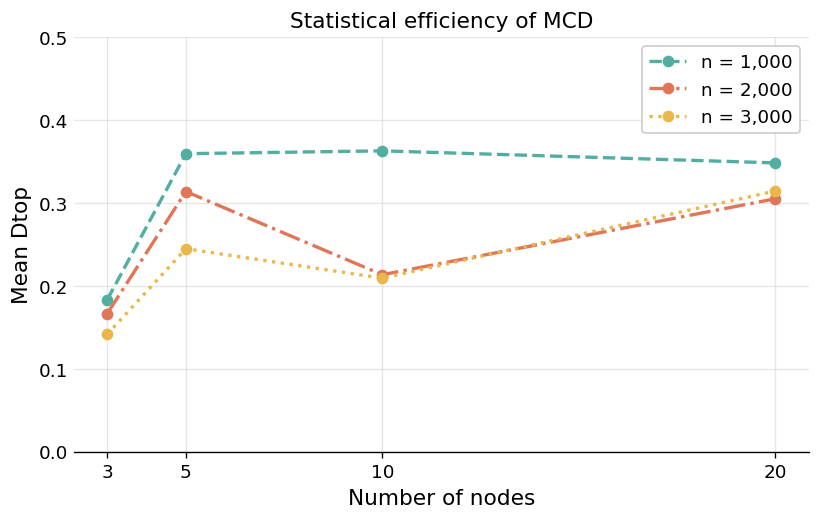

In [ ]:
df_mcd_eff = load_csv("mcd-hsic", 3, "not_obs_id")

d_values = sorted(df_mcd_eff["d"].unique())
n_samples_values = sorted(df_mcd_eff["n_samples"].unique())

LINESTYLES = ["--", "-.", ":"]
LINE_COLORS = ["#52AEA0", "#E07558", "#EAB84A"]

fig, ax = plt.subplots(figsize=(7, 4.5))
style_ax(ax)

for i, n_samp in enumerate(n_samples_values):
    sub = df_mcd_eff[df_mcd_eff["n_samples"] == n_samp]
    means = []
    for d in d_values:
        vals = sub.loc[sub["d"] == d, "dtop"].values
        means.append(np.mean(vals) if len(vals) > 0 else np.nan)

    ax.plot(d_values, means, linestyle=LINESTYLES[i], marker="o",
            color=LINE_COLORS[i], linewidth=2, markersize=6,
            label=f"n = {n_samp:,}")

ax.set_xlabel("Number of nodes")
ax.set_ylabel("Dtop")
ax.set_ylim(0, 0.5)
ax.set_yticks(np.arange(0, 0.51, 0.1))
ax.set_xticks(d_values)
ax.set_title("Statistical efficiency of MCD")
fix_legend(ax.legend())
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "paper_mcd_efficiency.pdf", bbox_inches="tight")
plt.show()


## 3. Effect of adding environments

Grouped bar chart with 3 bars per node count (n_envs = 3, 5, 7), MCD only, averaged over all n_samples. n_envs = 3 uses nn_residual data; n_envs = 5, 7 use not_obs_id (the only available mechanism for those counts).

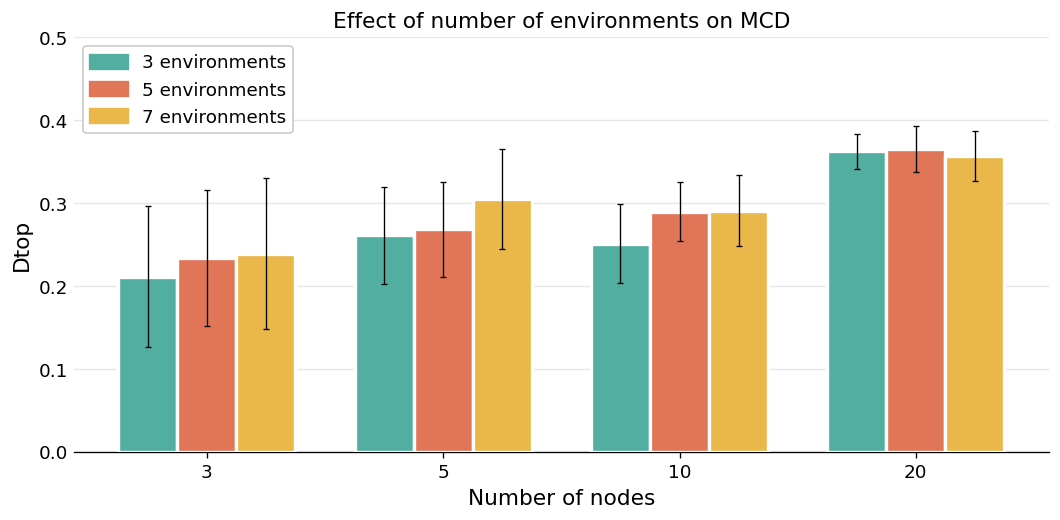

In [99]:
# n_envs=3 -> nn_residual; n_envs=5,7 -> not_obs_id (only available mechanism)
env_data = {}
for n_envs, mech in [(3, "nn_residual"), (5, "not_obs_id"), (7, "not_obs_id")]:
    df = load_csv("mcd-hsic", n_envs, mech)
    if df is not None:
        env_data[n_envs] = df

d_values = sorted(next(iter(env_data.values()))["d"].unique())
env_counts = [3, 5, 7]
bar_width = 0.25
x = np.arange(len(d_values))
env_colors = {3: "#52AEA0", 5: "#E07558", 7: "#EAB84A"}

fig, ax = plt.subplots(figsize=(9, 4.5))
style_ax(ax)
n_envs_present = [e for e in env_counts if e in env_data]

for i, n_envs in enumerate(n_envs_present):
    df = env_data[n_envs]
    means, cis = [], []
    for d in d_values:
        vals = df.loc[df["d"] == d, "dtop"].values
        means.append(np.mean(vals) if len(vals) > 0 else np.nan)
        cis.append(ci95(vals) if len(vals) > 0 else 0.0)

    offsets = x + (i - (len(n_envs_present) - 1) / 2) * bar_width
    ax.bar(offsets, means, width=bar_width, label=f"{n_envs} environments",
           color=env_colors[n_envs], edgecolor="white", linewidth=2,
           yerr=cis, capsize=ERR_KW["capsize"], error_kw=ERR_KW, zorder=3)

ax.set_xlabel("Number of nodes")
ax.set_ylabel("Dtop")
ax.set_ylim(0, 0.5)
ax.set_yticks(np.arange(0, 0.51, 0.1))
ax.set_xticks(x)
ax.set_xticklabels(d_values)
ax.set_title("Effect of number of environments on MCD")
fix_legend(ax.legend())
ax.grid(axis="y", alpha=0.3, zorder=0)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "paper_env_effect.pdf", bbox_inches="tight")
plt.show()


## 4. Ablation study — linear vs. nn_residual data

MCD with n_envs = 3. One bar per node count, averaged over all n_samples. Left: linear data. Right: NN residual data.

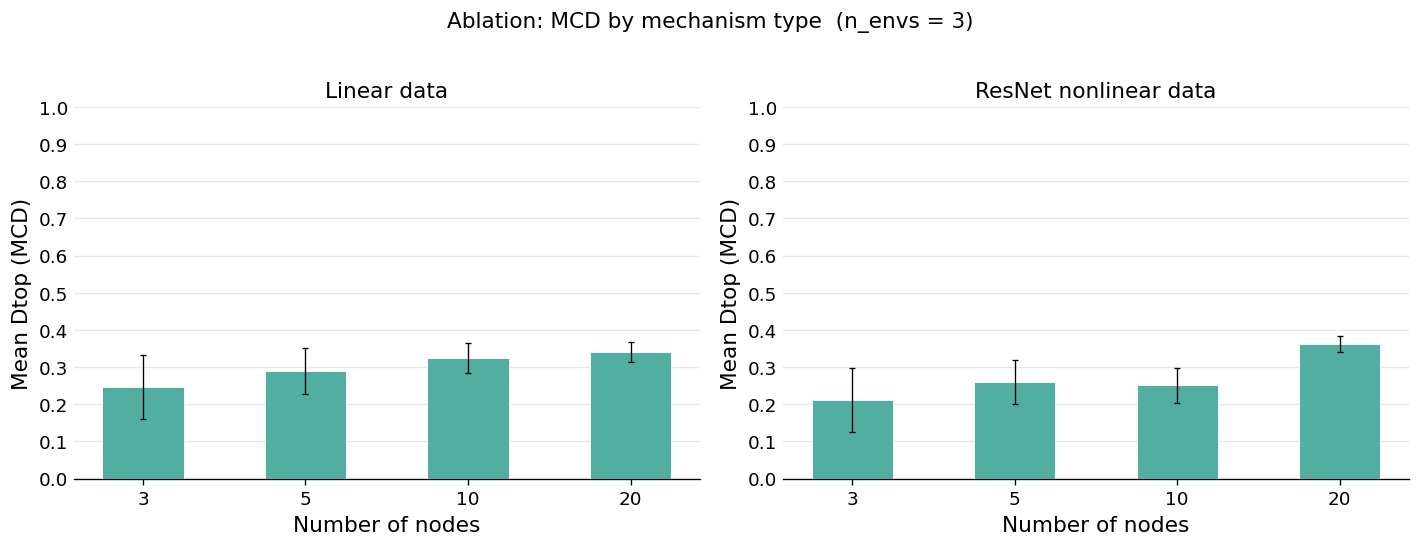

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ABLATION_DATA = [
    ("linear",      "Linear data"),
    ("nn_residual", "ResNet nonlinear data"),
]

for ax, (mech, title) in zip(axes, ABLATION_DATA):
    style_ax(ax)
    df = load_csv("mcd-hsic", 3, mech)
    if df is None:
        ax.set_title(f"{title} (data unavailable)")
        continue

    d_values = sorted(df["d"].unique())
    means, cis = [], []
    for d in d_values:
        vals = df.loc[df["d"] == d, "dtop"].values
        means.append(np.mean(vals))
        cis.append(ci95(vals))

    ax.bar(range(len(d_values)), means, yerr=cis,
           capsize=ERR_KW["capsize"], error_kw=ERR_KW,
           color="#52AEA0", edgecolor="white", linewidth=0.5, width=0.5, zorder=3)
    ax.set_xlabel("Number of nodes")
    ax.set_ylabel("Mean Dtop (MCD)")
    ax.set_ylim(0, 1.0)
    ax.set_yticks(np.arange(0, 1.01, 0.1))
    ax.set_xticks(range(len(d_values)))
    ax.set_xticklabels(d_values)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3, zorder=0)

plt.suptitle("Ablation: MCD by mechanism type", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "paper_ablation.pdf", bbox_inches="tight")
plt.show()
